# The final model: one search of the settings, and the holdout

Notebooks 02 to 12 built a model one table at a time on fixed settings. This notebook does the two things that were left to the end.

1. **Search the settings once, for the final feature list.** The settings were found in notebook 02 for 55 application features. The model now has 111 features from five tables. Notebooks 08 and 12 each checked two settings and found them leaning, inside the noise, towards more trees and fewer features per tree. This is the last chance to look properly, and the only one after all the features are in.
2. **Open the holdout.** 61,503 applicants, 20% of train, were set aside before any model was built and have not been looked at since notebook 02, where the application-only model scored 0.7715 on them. They are scored once more here, for the final model, and nothing is chosen after.

## Where things stand

| Model | Features | Cross-validation | Kaggle private |
|---|---:|---:|---:|
| Application only (notebook 02) | 36 | 0.7685 | 0.7638 |
| With the credit bureau (notebook 04) | 60 | 0.7779 | 0.7753 |
| With earlier applications (notebook 06) | 85 | 0.7856 | 0.7842 |
| With the payment record (notebook 08) | 108 | 0.7932 | 0.7934 |
| With credit card use (notebook 12) | 111 | 0.7948 | 0.7943 |

## The rule for changing the settings, fixed now

As in notebook 04. The current settings stay unless new ones beat them **twice**:

1. **In the search**: the best trial must beat trial 0, which is the current settings under the same protocol, by all four conditions on the five development folds.
2. **At the final learning rate**: refitted with the learning rate of 0.02 and a number of trees read off a curve, it must again beat the current model by all four conditions.

A search tries many settings and reports the best, so its winner is partly the best by luck. Requiring it to win again under different conditions guards against that.

**The search.** The protocol of notebooks 02 and 04: 30 trials of Optuna's TPE sampler, a learning rate of 0.05 with early stopping on 15% of the training folds set aside inside them, so that the validation fold decides nothing inside a trial. Trial 0 is the current settings. One change to the space, made before seeing any result: the share of features offered to each tree may go down to 15% instead of 30%, because with 111 features 30% is already 33 features, and both earlier checks pointed downwards.

## The holdout, fixed now

- The final model is fitted on the 246,008 development applicants only, with calibration, exactly as each fold's model was.
- It is scored once on the 61,503 holdout applicants. The holdout's outcomes are loaded in that cell and nowhere else.
- What is reported: ROC AUC with a 95% interval from resampling the holdout, PR AUC, log loss, calibration, and the decisions at the reference threshold. They are compared with the cross-validated figures and with the application-only model's 0.7715 on the same applicants.
- **Nothing is chosen on the holdout.** If its score were disappointing, the model would not be changed; the result would be reported.

| # | Stage |
|---|---|
| 1 | Setup, and the current model reproduced |
| 2 | The search |
| 3 | The winner refitted, and the number of trees |
| 4 | The final model |
| 5 | The holdout |
| 6 | Outputs and conclusions |

## Stage 1: Setup, and the current model reproduced

In [1]:
import ast, hashlib, inspect, json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nbformat
import joblib
import lightgbm, sklearn, scipy
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

PROCESSED, RAW = '../data/processed', '../data/raw'
CACHE_DIR = Path('../artifacts/cv_cache_13')
sys.path.insert(0, '../src/models')
import pipeline as shared
from pipeline import SEED, N_SPLITS, CategoryEncoder, KeepColumns, CalibratedModel, lgbm_model, make_pipeline, cross_validate, compare, score_predictions, logit

# 1.1 the six pieces copied from notebook 02 are still identical to their source there
notebook_02 = nbformat.read('02_model_selection_training.ipynb', 4)
original = {}
for cell in notebook_02.cells:
    if cell.cell_type != 'code':
        continue
    try:
        tree = ast.parse(cell.source)
    except SyntaxError:
        continue
    for node in tree.body:
        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
            original.setdefault(node.name, []).append(ast.get_source_segment(cell.source, node))
COPIED = ['CategoryEncoder', 'KeepColumns', 'CalibratedModel', 'logit', 'score_predictions', 'describe']
fidelity = {name: len(original.get(name, [])) == 1 and original[name][0].strip() == inspect.getsource(getattr(shared, name)).strip() for name in COPIED}
print('identical to notebook 02:', fidelity)
assert all(fidelity.values())
MODULE_CHECKSUM = hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest()
print(f"module checksum {MODULE_CHECKSUM[:12]} (the module has not changed since notebook 04, which notebooks 06, 08 and 10 also used, if this is 1379a001d7bb: {MODULE_CHECKSUM.startswith('1379a001d7bb')})")
print(f"results are cached in {CACHE_DIR.as_posix().replace('../', '')}")

identical to notebook 02: {'CategoryEncoder': True, 'KeepColumns': True, 'CalibratedModel': True, 'logit': True, 'score_predictions': True, 'describe': True}
module checksum 1379a001d7bb (the module has not changed since notebook 04, which notebooks 06, 08 and 10 also used, if this is 1379a001d7bb: True)
results are cached in artifacts/cv_cache_13


In [2]:
recipe = json.loads(Path('../artifacts/model_with_credit_cards/metadata.json').read_text(encoding='utf-8'))
FEATURES = list(recipe['features'])
BEST_PARAMS = dict(recipe['training']['lightgbm_settings'])
N_TREES, LEARNING_RATE = int(recipe['training']['trees']), float(recipe['training']['learning_rate'])
REFERENCE_CV = recipe['evidence']['cross_validation']
THRESHOLD = float(recipe['decision']['reference_threshold'])
FINAL = lambda: lgbm_model(BEST_PARAMS, N_TREES, LEARNING_RATE)
assert len(FEATURES) == 111 and N_TREES == 3500 and recipe['versions'] == {'python': sys.version.split()[0], 'lightgbm': lightgbm.__version__, 'pandas': pd.__version__, 'numpy': np.__version__,
                                                                            'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__}
print(f"final feature list: {len(FEATURES)} features {({k: len(v) for k, v in recipe['feature_sources'].items()})}; settings of notebook 02; {N_TREES:,} trees at {LEARNING_RATE}")

split = pd.read_parquet(f'{PROCESSED}/application_split.parquet')
application = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet')
application['REGION_RATING_CLIENT_W_CITY'] = application['REGION_RATING_CLIENT_W_CITY'].astype(float)
TABLES = ['bureau', 'previous', 'installments', 'credit_card']
meta = {name: json.loads(Path(f'{PROCESSED}/{name}_features_metadata.json').read_text(encoding='utf-8')) for name in TABLES}
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
joined = application.drop(columns='TARGET')
for name in TABLES:
    assert sha(f'{PROCESSED}/{name}_train_features.parquet') == meta[name]['tables']['train']['sha256']
    joined = joined.join(pd.read_parquet(f'{PROCESSED}/{name}_train_features.parquet'), how='left')
TEXT_FEATURES = [c for c in joined.columns if not pd.api.types.is_numeric_dtype(joined[c])]
is_dev = (split['split'] == 'dev').values
X_dev = joined.loc[is_dev].copy()                         # all columns, as in the earlier notebooks; the pipeline keeps the 111
y_arr = application.loc[is_dev, 'TARGET'].values
dev_fold = split.loc[is_dev, 'fold'].to_numpy()
HOLDOUT_IDS = split.index[~is_dev]
X_holdout = joined.loc[~is_dev].copy()          # features only; the holdout outcomes are loaded in stage 5 and nowhere else
del application, joined
assert len(X_dev) == 246008 and len(X_holdout) == 61503 and int(y_arr.sum()) == 19860
print(f"development {len(X_dev):,} applicants, holdout {len(X_holdout):,} (features only, outcomes not loaded)")

def run(features=FEATURES, model=None, seed=None):
    model = FINAL() if model is None else model
    if seed is not None:
        model.set_params(random_state=seed)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return cross_validate(make_pipeline(features, TEXT_FEATURES, model), X_dev, y_arr, dev_fold, cache_dir=CACHE_DIR)

NOTEBOOK_12_FOLDS = [0.79472, 0.79174, 0.79534, 0.79526, 0.79673]
started = time.time()
baseline = run()
print(f"current model: {'loaded' if baseline['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}; folds {baseline['folds']['roc_auc'].round(5).tolist()}; mean {baseline['mean']['roc_auc']:.5f} (notebook 12: {REFERENCE_CV['roc_auc']:.5f})")
assert abs(baseline['mean']['roc_auc'] - REFERENCE_CV['roc_auc']) < 1e-4 and np.allclose(baseline['folds']['roc_auc'].round(5), NOTEBOOK_12_FOLDS)
NOISE_FLOOR = 0.0005
def verdict(result, reference=None):
    c = compare(result, baseline if reference is None else reference)
    conditions = {'1. mean ROC AUC is higher': c['mean_difference'] > 0, '2. higher in at least four of five folds': c['folds_better'] >= 4,
                  '3. gain is more than twice its standard error': c['mean_difference'] > 0 and c['ratio_to_standard_error'] > 2, f'4. gain exceeds the noise floor of {NOISE_FLOOR}': c['mean_difference'] > NOISE_FLOOR}
    return {**c, 'conditions': conditions, 'improves': all(conditions.values())}

final feature list: 111 features {'application': 36, 'credit bureau': 24, 'previous applications': 25, 'instalment payments': 23, 'credit card': 3}; settings of notebook 02; 3,500 trees at 0.02


development 246,008 applicants, holdout 61,503 (features only, outcomes not loaded)


current model: loaded; folds [0.79472, 0.79174, 0.79534, 0.79526, 0.79673]; mean 0.79476 (notebook 12: 0.79476)


## Stage 2: The search

30 trials. Trial 0 is the current settings. Each trial is fitted on the five sets of training folds at a learning rate of 0.05, stopping when ROC AUC on 15% of the training rows, set aside inside them, has not improved for 100 trees. It is scored on the validation folds.

In [3]:
import lightgbm as lgb
warnings.filterwarnings('ignore', message='IProgress not found')
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS, SEARCH_RATE, MAX_TREES, PATIENCE = 30, 0.05, 4000, 100
SEARCH_DIR = CACHE_DIR / 'search'
SEARCH_DIR.mkdir(parents=True, exist_ok=True)
fold_data = []
for k in range(N_SPLITS):
    fit, val = dev_fold != k, dev_fold == k
    encoder = CategoryEncoder(columns=list(TEXT_FEATURES)).fit(X_dev[fit])
    X_fit, X_val = encoder.transform(X_dev[fit])[FEATURES], encoder.transform(X_dev[val])[FEATURES]
    grow, watch = train_test_split(np.arange(int(fit.sum())), test_size=0.15, stratify=y_arr[fit], random_state=SEED)
    fold_data.append({'X_fit': X_fit, 'y_fit': y_arr[fit], 'X_val': X_val, 'y_val': y_arr[val], 'grow': grow, 'watch': watch, 'val_rows': val})

def search_trial(params):
    key = hashlib.md5(json.dumps({'params': {k: repr(v) for k, v in sorted(params.items())}, 'features': FEATURES, 'protocol': [SEARCH_RATE, MAX_TREES, PATIENCE, SEED],
                                  'versions': [lightgbm.__version__, sklearn.__version__]}, sort_keys=True).encode()).hexdigest()
    path = SEARCH_DIR / f'{key}.joblib'
    if path.exists():
        return joblib.load(path)
    aucs, rounds, seconds, oof = [], [], [], np.zeros(len(y_arr))
    for d in fold_data:
        model = lgbm_model(params, MAX_TREES, SEARCH_RATE).set_params(metric='auc', first_metric_only=True)
        started = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            model.fit(d['X_fit'].iloc[d['grow']], d['y_fit'][d['grow']], eval_set=[(d['X_fit'].iloc[d['watch']], d['y_fit'][d['watch']])], eval_metric='auc',
                      callbacks=[lgb.early_stopping(PATIENCE, verbose=False)])
            prediction = model.predict_proba(d['X_val'])[:, 1]
        seconds.append(time.time() - started)
        oof[d['val_rows']] = prediction
        aucs.append(roc_auc_score(d['y_val'], prediction))
        rounds.append(int(model.best_iteration_))
    result = {'folds': aucs, 'rounds': rounds, 'seconds': float(np.sum(seconds)), 'oof': oof}
    joblib.dump(result, path, compress=3)
    return result

def suggest(trial):
    # the search space of notebooks 02 and 04, with the share of features per tree allowed down to 15%
    return {'num_leaves': trial.suggest_int('num_leaves', 8, 128, log=True), 'max_depth': trial.suggest_int('max_depth', 3, 12),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 1000, log=True), 'colsample_bytree': trial.suggest_float('colsample_bytree', 0.15, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True), 'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 100.0, log=True),
            'min_split_gain': trial.suggest_float('min_split_gain', 0.0, 0.5), 'cat_smooth': trial.suggest_float('cat_smooth', 1.0, 100.0, log=True),
            'neg_bagging_fraction': trial.suggest_float('neg_bagging_fraction', 0.1, 1.0), 'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 5.0)}

trial_results = {}
def objective(trial):
    params = suggest(trial)
    r = search_trial(params)
    trial_results[trial.number] = {**r, 'params': params}
    return float(np.mean(r['folds']))

started = time.time()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial(BEST_PARAMS)
study.optimize(objective, n_trials=N_TRIALS)
typical = float(np.median([r['seconds'] for r in trial_results.values()])) / 60
print(f"{N_TRIALS} trials in {(time.time() - started) / 60:.1f} minutes; a typical trial takes {typical:.1f} minutes")
trials = pd.DataFrame({n: {'roc_auc': np.mean(r['folds']), 'fold_sd': np.std(r['folds'], ddof=1), 'mean_trees': np.mean(r['rounds']), **r['params']} for n, r in trial_results.items()}).T
trials.index.name = 'trial'
current = trial_results[0]
assert all(abs(current['params'][k] - BEST_PARAMS[k]) < 1e-12 for k in BEST_PARAMS)
print(f"\ntrial 0, the current settings: ROC AUC {np.mean(current['folds']):.5f}, stopping after {np.mean(current['rounds']):.0f} trees on average")
print(f"trials that beat it: {int((trials['roc_auc'] > trials.loc[0, 'roc_auc']).sum())} of {N_TRIALS - 1}; best {trials['roc_auc'].max():.5f}")
print('\nthe ten best trials:')
print(trials.sort_values('roc_auc', ascending=False).head(10).to_string(float_format=lambda v: f'{v:.4f}'))

best_n = int(trials['roc_auc'].astype(float).idxmax())
best = trial_results[best_n]
diff = np.array(best['folds']) - np.array(current['folds'])
se = diff.std(ddof=1) / np.sqrt(N_SPLITS)
first_test = {'1. mean ROC AUC is higher': diff.mean() > 0, '2. higher in at least four of five folds': int((diff > 0).sum()) >= 4,
              '3. gain is more than twice its standard error': diff.mean() > 0 and diff.mean() > 2 * se, f'4. gain exceeds the noise floor of {NOISE_FLOOR}': diff.mean() > NOISE_FLOOR}
print(f"\nbest trial {best_n} against trial 0: {diff.mean():+.5f} (standard error {se:.5f}, better in {int((diff > 0).sum())} of 5 folds)")
for name, ok in first_test.items():
    print(f"{'MET    ' if ok else 'NOT MET'}  {name}")
PASSED_SEARCH = bool(best_n != 0 and all(first_test.values()))
print(f"first test of the rule: {'PASSED' if PASSED_SEARCH else 'NOT PASSED'}")

30 trials in 0.0 minutes; a typical trial takes 2.0 minutes

trial 0, the current settings: ROC AUC 0.79171, stopping after 1020 trees on average
trials that beat it: 9 of 29; best 0.79224

the ten best trials:
       roc_auc  fold_sd  mean_trees  num_leaves  max_depth  min_child_samples  colsample_bytree  reg_alpha  reg_lambda  min_split_gain  cat_smooth  neg_bagging_fraction  scale_pos_weight
trial                                                                                                                                                                                     
21      0.7922   0.0018   1422.4000      8.0000    12.0000           420.0000            0.3282     0.0018      0.1924          0.1658     13.0196                0.5087            1.6145
2       0.7922   0.0014   1191.6000      8.0000    12.0000           517.0000            0.3305     0.0053      0.0083          0.1521     11.2076                0.4888            2.1649
15      0.7919   0.0015   1024.8000     1

### Findings, stage 2

- **The current model was reproduced exactly** before the search: 0.79476, the same five fold scores as notebook 12.
- **Trial 0 (the current settings) scored 0.79171 under the search protocol.** This is lower than 0.79476 because each trial grows on 85% of the training folds at a learning rate of 0.05 and stops early. Every trial is handicapped the same way, so only differences between trials count.
- **9 of the other 29 trials beat it. The best, trial 21, beat it by +0.00053** (standard error 0.00015, better in 5 of 5 folds). That is just over the noise floor of 0.0005, so the first test is passed, but only narrowly. The search reports the best of 29 tries, so part of that margin is expected to be luck.
- **The two best trials agree on a region**: 8 leaves, depth 12, about 400 to 500 applicants per leaf instead of 803, a minimum split gain of about 0.15 instead of 0.01, a larger weight on defaults (1.6 to 2.2 instead of 1.2), and about a third of the features per tree, as now. The search did not move the share of features per tree below 0.23, despite the space allowing 0.15. The earlier checks' lean towards fewer features per tree is not confirmed here.
- **The ten best trials lie within 0.0005 of each other**, and the current settings are tenth. The score is flat across a wide range of settings. A large gain from new settings was never likely.

The winner goes on to the second test.

## Stage 3: The winner refitted, and the number of trees

The search ran at a learning rate of 0.05 with early stopping. The final model runs at 0.02 with a fixed number of trees. The winner has to win again under those conditions.

**Fixed before seeing the curves:**

- Both settings, the current ones and trial 21, are fitted once per fold at a learning rate of 0.02, up to 6,000 trees, on all the training-fold rows, and scored on the validation fold at several numbers of trees.
- **Each setting gets the number of trees where its own curve is highest.** The current settings were given their 3,500 trees the same way, in notebook 04. Comparing the winner at its best count against the current settings at a fixed count would favour the winner.
- **Second test**: the winner at its best count must beat the current settings at their best count by all four conditions, fold by fold.
- If it passes, the winner's settings are adopted, and the full pipeline with calibration is cross-validated to confirm it reproduces the curve. If it fails, the current settings stay. Their number of trees changes only by notebook 04's rule: a gain over 3,500 above the noise floor in at least four folds.

tree curves at learning rate 0.02: 0.0 minutes

       current settings  trial 21  difference  folds better
trees                                                      
2000            0.79340   0.79227    -0.00113             0
2500            0.79411   0.79312    -0.00099             0
3000            0.79453   0.79368    -0.00085             0
3500            0.79476   0.79400    -0.00076             0
4000            0.79480   0.79415    -0.00065             0
4500            0.79483   0.79430    -0.00053             0
5000            0.79473   0.79432    -0.00040             1
6000            0.79442   0.79435    -0.00007             2

check: the current settings' curve at 3,500 trees (0.79476) equals the pipeline's result (0.79476): True

best point of each curve: current settings 4,500 trees (0.79483), trial 21 6,000 trees (0.79435)
trial 21 at its best against the current settings at theirs: -0.00048 (standard error 0.00027, better in 2 of 5 folds)
NOT MET  1. mean ROC AUC is h

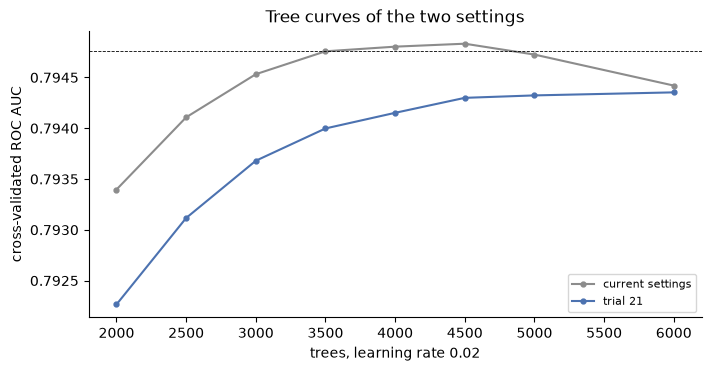

In [4]:
CANDIDATE_PARAMS = dict(best['params'])
CHECKPOINTS = [2000, 2500, 3000, 3500, 4000, 4500, 5000, 6000]
assert N_TREES in CHECKPOINTS
fold_columns = [f'fold {k}' for k in range(N_SPLITS)]

def tree_curve(params):
    path = CACHE_DIR / f"trees_{hashlib.md5(json.dumps({'p': {k: repr(v) for k, v in sorted(params.items())}, 'f': FEATURES, 'c': CHECKPOINTS, 'rate': LEARNING_RATE, 'seed': SEED}, sort_keys=True).encode()).hexdigest()}.joblib"
    if path.exists():
        curve = joblib.load(path)
    else:
        curve = {}
        for k, d in enumerate(fold_data):
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                model = lgbm_model(params, max(CHECKPOINTS), LEARNING_RATE).fit(d['X_fit'], d['y_fit'])    # all training-fold rows, as the pipeline's final model uses
                curve[k] = {n: roc_auc_score(d['y_val'], model.predict_proba(d['X_val'], num_iteration=n)[:, 1]) for n in CHECKPOINTS}
        joblib.dump(curve, path)
    curve = pd.DataFrame(curve)
    curve.columns = fold_columns
    curve['mean'] = curve[fold_columns].mean(axis=1)
    curve.index.name = 'trees'
    return curve

started = time.time()
WINNER = f'trial {best_n}'
cur, cand = tree_curve(BEST_PARAMS), tree_curve(CANDIDATE_PARAMS)
print(f"tree curves at learning rate {LEARNING_RATE}: {(time.time() - started) / 60:.1f} minutes\n")
side = pd.DataFrame({'current settings': cur['mean'], WINNER: cand['mean']})
side['difference'] = side[WINNER] - side['current settings']
side['folds better'] = [int((cand.loc[n, fold_columns] > cur.loc[n, fold_columns]).sum()) for n in CHECKPOINTS]
print(side.to_string(float_format=lambda v: f'{v:.5f}'))

same_as_pipeline = abs(cur.loc[N_TREES, 'mean'] - baseline['mean']['roc_auc'])
print(f"\ncheck: the current settings' curve at {N_TREES:,} trees ({cur.loc[N_TREES, 'mean']:.5f}) equals the pipeline's result ({baseline['mean']['roc_auc']:.5f}): {same_as_pipeline < 1e-9}")
assert same_as_pipeline < 1e-9, 'the curve and the pipeline must be the same model'

CURRENT_BEST, CANDIDATE_BEST = int(cur['mean'].idxmax()), int(cand['mean'].idxmax())
d = cand.loc[CANDIDATE_BEST, fold_columns].astype(float).values - cur.loc[CURRENT_BEST, fold_columns].astype(float).values
se = d.std(ddof=1) / np.sqrt(N_SPLITS)
second_test = {'1. mean ROC AUC is higher': d.mean() > 0, '2. higher in at least four of five folds': int((d > 0).sum()) >= 4,
               '3. gain is more than twice its standard error': d.mean() > 0 and d.mean() > 2 * se, f'4. gain exceeds the noise floor of {NOISE_FLOOR}': d.mean() > NOISE_FLOOR}
print(f"\nbest point of each curve: current settings {CURRENT_BEST:,} trees ({cur.loc[CURRENT_BEST, 'mean']:.5f}), {WINNER} {CANDIDATE_BEST:,} trees ({cand.loc[CANDIDATE_BEST, 'mean']:.5f})")
print(f"{WINNER} at its best against the current settings at theirs: {d.mean():+.5f} (standard error {se:.5f}, better in {int((d > 0).sum())} of 5 folds)")
for name, ok in second_test.items():
    print(f"{'MET    ' if ok else 'NOT MET'}  {name}")
ADOPT = bool(PASSED_SEARCH and all(second_test.values()))
print(f"second test of the rule: {'PASSED' if ADOPT else 'NOT PASSED'}")
against_now = cand.loc[CANDIDATE_BEST, fold_columns].astype(float).values - cur.loc[N_TREES, fold_columns].astype(float).values
print(f"(for reference, against the current model as it stands, {N_TREES:,} trees: {against_now.mean():+.5f}, better in {int((against_now > 0).sum())} of 5 folds)")

if ADOPT:
    FINAL_PARAMS, FINAL_TREES = dict(CANDIDATE_PARAMS), CANDIDATE_BEST
else:
    tree_gain = cur.loc[CURRENT_BEST, 'mean'] - cur.loc[N_TREES, 'mean']
    tree_folds = int((cur.loc[CURRENT_BEST, fold_columns] > cur.loc[N_TREES, fold_columns]).sum())
    FINAL_PARAMS = dict(BEST_PARAMS)
    FINAL_TREES = CURRENT_BEST if (tree_gain > NOISE_FLOOR and tree_folds >= 4) else N_TREES
    print(f"\ncurrent settings: best count {CURRENT_BEST:,}, {tree_gain:+.5f} against {N_TREES:,} in {tree_folds} of 5 folds -> {FINAL_TREES:,} trees")
CHANGED = FINAL_PARAMS != BEST_PARAMS or FINAL_TREES != N_TREES

def MODEL():
    # the final model, unfitted
    return lgbm_model(FINAL_PARAMS, FINAL_TREES, LEARNING_RATE)

if CHANGED:
    started = time.time()
    final_run = run(model=MODEL())
    print(f"\nfinal recipe cross-validated with calibration: {'loaded' if final_run['cached'] else f'{(time.time() - started) / 60:.1f} minutes'}; "
          f"{final_run['mean']['roc_auc']:.5f}, curve {(cand if ADOPT else cur).loc[FINAL_TREES, 'mean']:.5f}")
    assert abs(final_run['mean']['roc_auc'] - (cand if ADOPT else cur).loc[FINAL_TREES, 'mean']) < 1e-9
else:
    final_run = baseline
print(f"\ncarried forward: settings {'of ' + WINNER if ADOPT else 'of notebook 02'}, {FINAL_TREES:,} trees at {LEARNING_RATE}")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL_PARAMS.items()})

fig, ax = plt.subplots(figsize=(7, 3.6), layout='constrained')
for label, c, color in [('current settings', cur, '#8C8C8C'), (WINNER, cand, '#4C72B0')]:
    ax.plot(c.index, c['mean'], marker='o', markersize=3.5, color=color, label=label)
ax.axhline(baseline['mean']['roc_auc'], color='black', linewidth=0.6, linestyle='--')
ax.set_xlabel('trees, learning rate 0.02'); ax.set_ylabel('cross-validated ROC AUC'); ax.set_title('Tree curves of the two settings')
ax.legend(fontsize=8)
sns.despine()
plt.show()

### Findings, stage 3

- **Trial 21 failed the second test clearly.** At a learning rate of 0.02, it scored below the current settings at every number of trees up to 5,000. At its best, 6,000 trees, it was 0.00048 below the current settings at their best and better in only 2 of 5 folds. None of the four conditions were met.
- **Its win in the search was an artefact of the search protocol, not a better model.** Trial 21 has a large minimum split gain (0.17) and leaves of about 400 applicants. Its curve was still rising at 6,000 trees: it learns more slowly per tree. Under early stopping at 0.05, that suited it. At the final learning rate, the current settings get further with fewer trees. This is the case the two-test rule was written for.
- **The current settings keep 3,500 trees.** Their curve peaks at 4,500 trees, but only +0.00007 higher, in 2 of 5 folds: well inside the noise.
- **Nothing changes.** The final model is notebook 12's: 111 features, the settings of notebook 02, 3,500 trees at 0.02, Platt calibration. Notebook 12's development-set model and its saved model on all of train are used as they are.

## Stage 4: The final model, cross-validated

The recipe carried forward is: the 111 features, the settings and number of trees from stage 3, Platt calibration fitted inside the training rows, and the reference threshold of 0.0909 from notebook 02 (cost ratio 10). Below are its cross-validated figures, the last ones before the holdout is opened.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss, brier_score_loss

def calibration_line(y, p):
    fit = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
    return float(fit.coef_[0, 0]), float(fit.intercept_[0])

def reliability(y, p, bins=10):
    groups = pd.qcut(pd.Series(p).rank(method='first'), bins, labels=False)
    return pd.DataFrame({'predicted_pct': pd.Series(p).groupby(groups).mean() * 100, 'actual_pct': pd.Series(y).groupby(groups).mean() * 100, 'rows': pd.Series(y).groupby(groups).size()})

def decisions(y, p, threshold=THRESHOLD):
    declined = p >= threshold
    return {'declined %': declined.mean() * 100, 'defaults caught %': declined[y == 1].mean() * 100, 'default rate among approved %': y[~declined].mean() * 100,
            'default rate among declined %': y[declined].mean() * 100}

def report(y, p):
    slope, intercept = calibration_line(y, p)
    t = reliability(y, p)
    return {'ROC AUC': roc_auc_score(y, p), 'PR AUC': average_precision_score(y, p), 'log loss': log_loss(y, np.clip(p, 1e-7, 1 - 1e-7)), 'Brier score': brier_score_loss(y, p),
            'average prediction %': p.mean() * 100, 'actual default rate %': y.mean() * 100, 'calibration slope': slope, 'calibration intercept': intercept,
            'largest gap in a tenth (pts)': float((t['predicted_pct'] - t['actual_pct']).abs().max()), **decisions(y, p)}

FINAL_CV = float(final_run['mean']['roc_auc'])
# the folds above score the model before calibration (the ranking, which calibration does not change); calibration and decisions need the calibrated recipe
started = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    final_cal = cross_validate(make_pipeline(FEATURES, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt')), X_dev, y_arr, dev_fold,
                               cache_dir=CACHE_DIR if CHANGED else Path('../artifacts/cv_cache_12'))
print(f"calibrated recipe cross-validated: {'loaded from notebook 12' if final_cal['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
if not CHANGED:
    assert abs(final_cal['mean']['log_loss'] - REFERENCE_CV['log_loss']) < 1e-9 and abs(final_cal['mean']['pr_auc'] - REFERENCE_CV['pr_auc']) < 1e-9
assert np.allclose(final_cal['folds']['roc_auc'], final_run['folds']['roc_auc'], atol=1e-9)
cv_report = report(y_arr, final_cal['oof'])
cv_table = pd.DataFrame({'final model, cross-validated': cv_report, 'before calibration': report(y_arr, final_run['oof'])})
cv_table.loc['ROC AUC, mean of the folds'] = [FINAL_CV, FINAL_CV]
print(cv_table.to_string(float_format=lambda v: f'{v:.4f}'))
print(f"\nfold scores: {final_run['folds']['roc_auc'].round(5).tolist()} (spread {final_run['folds']['roc_auc'].max() - final_run['folds']['roc_auc'].min():.5f})")
print(f"the final model {'is' if not CHANGED else 'is not'} the notebook 12 model; calibration leaves the ranking, and so the ROC AUC, unchanged")

calibrated recipe cross-validated: loaded from notebook 12


                               final model, cross-validated  before calibration
ROC AUC                                              0.7947              0.7947
PR AUC                                               0.2874              0.2874
log loss                                             0.2347              0.2497
Brier score                                          0.0655              0.0697
average prediction %                                 8.1194             13.1501
actual default rate %                                8.0729              8.0729
calibration slope                                    1.0172              0.9995
calibration intercept                                0.0269             -0.6337
largest gap in a tenth (pts)                         0.7313             14.6052
declined %                                          27.9975             46.5509
defaults caught %                                   68.3837             84.5015
default rate among approved %           

### Findings, stage 4

- **The final model is notebook 12's model.** Its calibrated cross-validation was loaded from notebook 12's cache and matches it exactly: ROC AUC 0.7948 (mean of the folds), PR AUC 0.2874, log loss 0.2347.
- **Calibration matters for the figures, not the ranking.** Before calibration, the model predicts 13.2% on average, because it gives defaults extra weight in training. That would decline 46.6% of applicants at the reference threshold. After Platt calibration, it predicts 8.12% against an actual 8.07%, with a slope of 1.02 and no tenth more than 0.73 points off. At the reference threshold it declines 28.0% of applicants and catches 68.4% of defaults, and 3.54% of the approved default.
- These are the figures the holdout is compared with.

## Stage 5: The holdout

**Fixed now, before the outcomes are loaded:**

1. **The models scored.** The final recipe, fitted with calibration on the 246,008 development applicants. Alongside it, notebook 02's application-only recipe, refitted the same way. That refit is checked against notebook 02's holdout score of 0.7715, so the gain from the four extra tables is measured on the same applicants.
2. **Agreement.** As in notebook 02: the holdout agrees with cross-validation if its ROC AUC is within 0.008 of the cross-validated score. The interval is printed below before opening. Notebook 02's application-only model scored 0.0030 higher on the holdout than in cross-validation, so a small positive difference would not be surprising.
3. **The gain carries over** if the final model beats the application-only model on the holdout by at least half its cross-validated gain, and the 95% interval of the paired difference, from resampling, excludes zero.
4. **Calibration holds** if the average prediction is within 0.5 points of the actual default rate and the calibration slope is between 0.9 and 1.1.
5. **Nothing is chosen here.** Whatever the holdout shows is reported. The model is not changed.

The outcomes of the 61,503 holdout applicants are loaded in the second cell below, and nowhere else in this project after notebook 02.

In [6]:
MODEL_DIR = CACHE_DIR / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def model_tag(prefix, features, params, trees, rows):
    spec = {'features': list(features), 'params': {k: repr(v) for k, v in sorted(params.items())}, 'trees': trees, 'rate': LEARNING_RATE, 'rows': rows, 'seed': SEED,
            'module': hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest(), 'versions': [lightgbm.__version__, sklearn.__version__]}
    return prefix + '_' + hashlib.md5(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:16]

def fitted(tag, build, also_look_in=()):
    for folder in (MODEL_DIR, *also_look_in):
        path = Path(folder) / f'{tag}.joblib'
        if path.exists():
            return joblib.load(path), f'loaded from {path.parent.as_posix().replace("../", "")}'
    started = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        model = build()
    joblib.dump(model, MODEL_DIR / f'{tag}.joblib', compress=3)
    return model, f'fitted in {(time.time() - started) / 60:.1f} minutes'

recipe_02 = json.loads(Path('../artifacts/final_model/metadata.json').read_text(encoding='utf-8'))
APP_FEATURES, APP_PARAMS, APP_TREES = list(recipe_02['features']), dict(recipe_02['training']['lightgbm_settings']), int(recipe_02['training']['trees'])
assert len(APP_FEATURES) == 36 and set(APP_FEATURES) <= set(FEATURES) and recipe_02['training']['learning_rate'] == LEARNING_RATE

# the final recipe on the development set; if nothing changed, this is the model notebook 12 fitted and explained
final_dev, how = fitted(model_tag('dev_with_cards', FEATURES, FINAL_PARAMS, FINAL_TREES, 'dev'),
                        lambda: make_pipeline(FEATURES, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt')).fit(X_dev, y_arr), also_look_in=['../artifacts/cv_cache_12/models'])
print(f"final model on the development set: {how}")
app_dev, how = fitted(model_tag('dev_application_only', APP_FEATURES, APP_PARAMS, APP_TREES, 'dev'),
                      lambda: make_pipeline(APP_FEATURES, TEXT_FEATURES, CalibratedModel(lgbm_model(APP_PARAMS, APP_TREES, LEARNING_RATE), method='platt')).fit(X_dev, y_arr))
print(f"application-only model on the development set: {how}")

p_hold = final_dev.predict_proba(X_holdout)[:, 1]
p_hold_app = app_dev.predict_proba(X_holdout)[:, 1]
assert np.isfinite(p_hold).all() and np.isfinite(p_hold_app).all()

AGREEMENT_BAND = (round(FINAL_CV - 0.008, 4), round(FINAL_CV + 0.008, 4))
APP_CV = float(recipe_02['evidence']['cross_validation']['roc_auc'])
CV_GAIN = FINAL_CV - APP_CV
plan = pd.Series({
    'model': f"LightGBM, {len(FEATURES)} features from five tables, {FINAL_TREES:,} trees at {LEARNING_RATE}, settings {'of ' + WINNER if ADOPT else 'of notebook 02'}, Platt calibration",
    'trained on': f"the {len(X_dev):,} development applicants only",
    'cross-validated ROC AUC': f"{FINAL_CV:.4f}",
    '1. agreement': f"holdout ROC AUC between {AGREEMENT_BAND[0]:.4f} and {AGREEMENT_BAND[1]:.4f}",
    '2. the gain carries over': f"holdout gain over the application-only model of at least {CV_GAIN / 2:.4f} (half of the cross-validated {CV_GAIN:.4f}), interval above zero",
    '3. calibration': 'average prediction within 0.5 points of the default rate; slope between 0.9 and 1.1',
    'if the holdout disagrees': 'report it; change nothing',
})
print()
print(plan.to_string())
print(f"\npredictions made for {len(p_hold):,} holdout applicants; outcomes not yet loaded")

final model on the development set: loaded from artifacts/cv_cache_12/models
application-only model on the development set: loaded from artifacts/cv_cache_13/models



model                       LightGBM, 111 features from five tables, 3,500...
trained on                            the 246,008 development applicants only
cross-validated ROC AUC                                                0.7948
1. agreement                        holdout ROC AUC between 0.7868 and 0.8028
2. the gain carries over    holdout gain over the application-only model o...
3. calibration              average prediction within 0.5 points of the de...
if the holdout disagrees                            report it; change nothing

predictions made for 61,503 holdout applicants; outcomes not yet loaded


check: the application-only refit scores 0.7715 on the holdout; notebook 02 reported 0.7715: True



                               final model, cross-validated  final model, holdout  application only, holdout  holdout minus cross-validated
ROC AUC                                              0.7947                0.7947                     0.7715                        -0.0000
PR AUC                                               0.2874                0.2983                     0.2644                         0.0109
log loss                                             0.2347                0.2338                     0.2417                        -0.0009
Brier score                                          0.0655                0.0651                     0.0668                        -0.0004
average prediction %                                 8.1194                8.1226                     8.0778                         0.0031
actual default rate %                                8.0729                8.0728                     8.0728                        -0.0001
calibration slope  

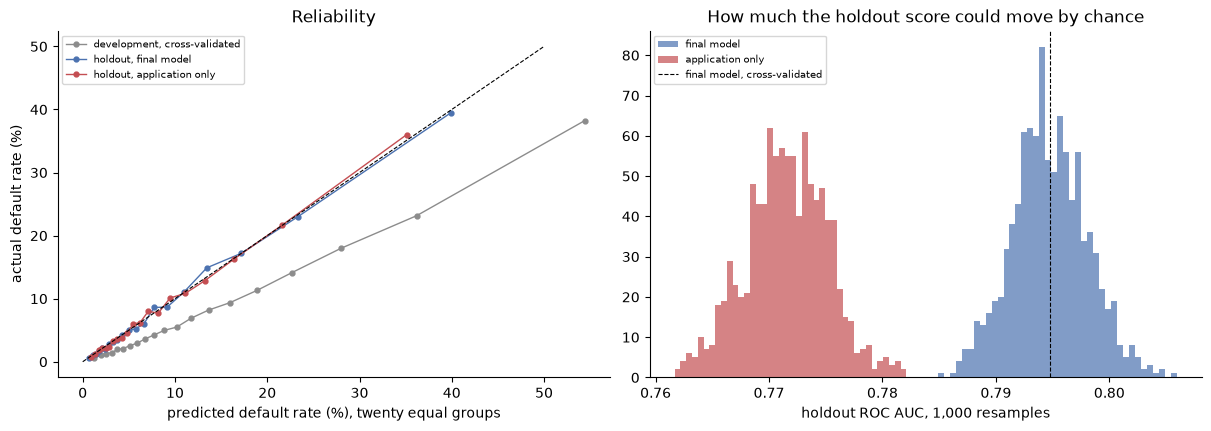

In [7]:
# THE ONE OPENING OF THE HOLDOUT FOR THE FINAL MODEL: outcomes loaded here and nowhere else
assert X_holdout.index.equals(pd.Index(HOLDOUT_IDS))
y_hold = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['TARGET']).loc[HOLDOUT_IDS, 'TARGET'].to_numpy()
assert len(y_hold) == 61503 and int(y_hold.sum()) == 4965

hold_final, hold_app = report(y_hold, p_hold), report(y_hold, p_hold_app)
print(f"check: the application-only refit scores {hold_app['ROC AUC']:.4f} on the holdout; notebook 02 reported {recipe_02['evidence']['holdout']['roc_auc']:.4f}: "
      f"{abs(hold_app['ROC AUC'] - recipe_02['evidence']['holdout']['roc_auc']) < 1e-6}")

rng = np.random.default_rng(SEED)
N_BOOT = 1000
boot = np.empty((N_BOOT, 2))
for b in range(N_BOOT):
    idx = rng.integers(0, len(y_hold), len(y_hold))
    boot[b] = roc_auc_score(y_hold[idx], p_hold[idx]), roc_auc_score(y_hold[idx], p_hold_app[idx])
low, high = np.percentile(boot[:, 0], [2.5, 97.5])
gain_low, gain_high = np.percentile(boot[:, 0] - boot[:, 1], [2.5, 97.5])
HOLD_AUC, HOLD_GAIN = hold_final['ROC AUC'], hold_final['ROC AUC'] - hold_app['ROC AUC']

headline = pd.DataFrame({'final model, cross-validated': cv_report, 'final model, holdout': hold_final, 'application only, holdout': hold_app})
headline['holdout minus cross-validated'] = headline['final model, holdout'] - headline['final model, cross-validated']
print()
print(headline.to_string(float_format=lambda v: f'{v:.4f}'))

outcome = {
    '1. agreement': AGREEMENT_BAND[0] <= HOLD_AUC <= AGREEMENT_BAND[1],
    '2. the gain carries over': HOLD_GAIN >= CV_GAIN / 2 and gain_low > 0,
    '3. calibration': abs(hold_final['average prediction %'] - hold_final['actual default rate %']) <= 0.5 and 0.9 <= hold_final['calibration slope'] <= 1.1,
}
print(f"\nholdout ROC AUC {HOLD_AUC:.4f} (95% interval from {N_BOOT} resamples: {low:.4f} to {high:.4f}); cross-validated {FINAL_CV:.4f}; difference {HOLD_AUC - FINAL_CV:+.4f}")
print(f"gain over the application-only model: holdout {HOLD_GAIN:+.4f} (interval {gain_low:+.4f} to {gain_high:+.4f}); cross-validated {CV_GAIN:+.4f}")
for name, ok in outcome.items():
    print(f"{'AS EXPECTED ' if ok else 'NOT AS EXPECTED'}  {name}")

source_of = {c: k for k, members in recipe['feature_sources'].items() for c in members}
groups = {}
for table in ['credit bureau', 'previous applications', 'instalment payments', 'credit card']:
    has = X_holdout[[c for c in FEATURES if source_of[c] == table]].notna().any(axis=1).to_numpy()
    for label, rows in [('with a record', has), ('without', ~has)]:
        if y_hold[rows].sum() >= 50:
            groups[(table, label)] = {'applicants': int(rows.sum()), 'default rate %': y_hold[rows].mean() * 100, 'final model': roc_auc_score(y_hold[rows], p_hold[rows]),
                                      'application only': roc_auc_score(y_hold[rows], p_hold_app[rows])}
groups = pd.DataFrame(groups).T
groups['gain'] = groups['final model'] - groups['application only']
print('\nholdout ROC AUC by whether the applicant has a record in each table:')
print(groups.to_string(float_format=lambda v: f'{v:,.4f}'))

tenths = reliability(y_hold, p_hold)
tenths['share of defaults %'] = tenths['actual_pct'] * tenths['rows'] / (tenths['actual_pct'] * tenths['rows']).sum() * 100
tenths_app = reliability(y_hold, p_hold_app)
tenths_app['share of defaults %'] = tenths_app['actual_pct'] * tenths_app['rows'] / (tenths_app['actual_pct'] * tenths_app['rows']).sum() * 100
print('\nholdout, by tenth of predicted risk (final model):')
print(tenths.round(2).T.to_string())
print(f"riskiest tenth holds {tenths['share of defaults %'].iloc[-1]:.1f}% of all defaults (application only: {tenths_app['share of defaults %'].iloc[-1]:.1f}%); "
      f"riskiest three tenths {tenths['share of defaults %'].iloc[-3:].sum():.1f}% ({tenths_app['share of defaults %'].iloc[-3:].sum():.1f}%); safest tenth defaults at {tenths['actual_pct'].iloc[0]:.2f}% ({tenths_app['actual_pct'].iloc[0]:.2f}%)")

HOLDOUT_RESULT = {'roc_auc': float(HOLD_AUC), 'interval': [float(low), float(high)], 'pr_auc': float(hold_final['PR AUC']), 'log_loss': float(hold_final['log loss']),
                  'cv_roc_auc': FINAL_CV, 'application_only_roc_auc': float(hold_app['ROC AUC']), 'gain_over_application_only': float(HOLD_GAIN),
                  'gain_interval': [float(gain_low), float(gain_high)], 'rows': int(len(y_hold)), 'defaults': int(y_hold.sum()), 'expectations_met': {k: bool(v) for k, v in outcome.items()}}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
for label, yy, pp, color in [('development, cross-validated', y_arr, final_run['oof'], '#8C8C8C'), ('holdout, final model', y_hold, p_hold, '#4C72B0'), ('holdout, application only', y_hold, p_hold_app, '#C44E52')]:
    r = reliability(yy, pp, bins=20)
    axes[0].plot(r['predicted_pct'], r['actual_pct'], marker='o', markersize=3.5, linewidth=1, color=color, label=label)
axes[0].plot([0, 50], [0, 50], color='black', linewidth=0.8, linestyle='--')
axes[0].set_xlabel('predicted default rate (%), twenty equal groups'); axes[0].set_ylabel('actual default rate (%)'); axes[0].set_title('Reliability'); axes[0].legend(fontsize=7)
axes[1].hist(boot[:, 0], bins=40, color='#4C72B0', alpha=0.7, label='final model')
axes[1].hist(boot[:, 1], bins=40, color='#C44E52', alpha=0.7, label='application only')
axes[1].axvline(FINAL_CV, color='black', linestyle='--', linewidth=0.8, label='final model, cross-validated')
axes[1].set_xlabel('holdout ROC AUC, 1,000 resamples'); axes[1].set_title('How much the holdout score could move by chance'); axes[1].legend(fontsize=7)
sns.despine()
plt.show()

### Findings, stage 5: the holdout

- **The holdout agrees with cross-validation, to the fourth decimal.** ROC AUC 0.7947 (95% interval 0.7883 to 0.8014), against 0.7948 cross-validated, well inside the agreement range of 0.7868 to 0.8028 fixed beforehand. Log loss 0.2338 against 0.2347; PR AUC 0.2983 against 0.2874. Twelve notebooks of feature and model choices, all made on the development folds, did not overfit them.
- **The gain from the four extra tables carries over.** The application-only model, refitted the same way, reproduces notebook 02's holdout score of 0.7715 exactly. The final model beats it on the same applicants by +0.0232 (interval +0.0193 to +0.0269), against +0.0262 in cross-validation: 89% of the cross-validated gain. Part of the cross-validated gain was choice on those folds, as expected, but most of it is real.
- **Calibration holds.** Average prediction 8.12% against an actual 8.07%, slope 1.01, no tenth more than 0.73 points off.
- **For decisions:** at the reference threshold, the final model declines fewer applicants than the application-only model (27.6% against 28.9%) and catches more defaults (68.3% against 65.6%). The default rate among the approved falls from 3.91% to 3.54%. The riskiest tenth holds 38.7% of all defaults, against 35.8%.
- **The gain reaches every group.** It is largest for applicants with no credit bureau record (+0.030): for them, the earlier applications and payment record replace the missing bureau history. It is next largest for card holders (+0.028). It is smallest for the 3,182 applicants with no instalment record (+0.017).
- **All three expectations were met. Nothing was changed.** The holdout cell runs again each time the notebook is executed, and gives the same numbers, because every model it scores is fixed and loaded from file. Nothing was chosen from it.

## Stage 6: Outputs

The settings did not change, so the model saved by notebook 12 in `artifacts/model_with_credit_cards/` is the final model, and its submission (Kaggle private 0.79428, public 0.79326) stands. No new submission is needed. This stage saves the holdout result beside the model without touching the model itself, and puts the whole project in one table.

In [8]:
assert not CHANGED, 'this stage is written for the unchanged model'
FINAL_DIR = Path('../artifacts/model_with_credit_cards')
saved = json.loads((FINAL_DIR / 'metadata.json').read_text(encoding='utf-8'))
model_sha = hashlib.sha256((FINAL_DIR / 'model.txt').read_bytes()).hexdigest()
output_checks = {
    'the saved model is the one notebook 12 wrote (checksum)': model_sha == saved['files']['model_sha256'],
    'it uses the 111 features and settings scored here': saved['features'] == FEATURES and saved['training']['lightgbm_settings'] == recipe['training']['lightgbm_settings'] and saved['training']['trees'] == FINAL_TREES,
}
evaluation = {
    'model': 'artifacts/model_with_credit_cards (notebook 12), unchanged',
    'model_sha256': model_sha,
    'note': ('The holdout was scored once, in notebook 13, with the same recipe fitted on the 246,008 development applicants only. '
             'The saved model was fitted on all of train, holdout included, so it has not itself been scored on the holdout.'),
    'holdout': HOLDOUT_RESULT,
    'cross_validation': {'roc_auc': FINAL_CV, 'pr_auc': float(final_cal['mean']['pr_auc']), 'log_loss': float(final_cal['mean']['log_loss'])},
    'kaggle': {'private': 0.79428, 'public': 0.79326},
    'settings_search': {'trials': N_TRIALS, 'best_trial': int(best_n), 'first_test_passed': bool(PASSED_SEARCH), 'second_test_passed': bool(ADOPT),
                        'best_trial_at_final_rate_minus_current': float(d.mean()), 'outcome': 'settings of notebook 02 kept, 3,500 trees'},
}
(FINAL_DIR / 'holdout_evaluation.json').write_text(json.dumps(evaluation, indent=2), encoding='utf-8')
output_checks['holdout_evaluation.json reads back'] = json.loads((FINAL_DIR / 'holdout_evaluation.json').read_text(encoding='utf-8'))['holdout']['roc_auc'] == HOLDOUT_RESULT['roc_auc']
output_checks['the model file is untouched after writing'] = hashlib.sha256((FINAL_DIR / 'model.txt').read_bytes()).hexdigest() == model_sha
for name, ok in output_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(output_checks.values())

project = pd.DataFrame([
    ('02', 'application only', 36, 0.7685, 0.7715, 0.76382),
    ('04', '+ credit bureau', 60, 0.7779, None, 0.7753),
    ('06', '+ earlier applications', 85, 0.7856, None, 0.78421),
    ('08', '+ instalment payments', 108, 0.79316, None, 0.79337),
    ('10', '+ POS and cash loans (left out)', 108, None, None, None),
    ('12', '+ credit cards, final', 111, round(FINAL_CV, 5), round(HOLDOUT_RESULT['roc_auc'], 5), 0.79428),
], columns=['notebook', 'model', 'features', 'cross-validated ROC AUC', 'holdout ROC AUC', 'Kaggle private']).set_index('notebook')
print()
print(project.to_string(na_rep='-'))
print(f"\nfrom the application-only model to the final model: cross-validated {FINAL_CV - 0.7685:+.4f}, holdout {HOLDOUT_RESULT['gain_over_application_only']:+.4f}, Kaggle private {0.79428 - 0.76382:+.4f}")

PASS  the saved model is the one notebook 12 wrote (checksum)
PASS  it uses the 111 features and settings scored here
PASS  holdout_evaluation.json reads back
PASS  the model file is untouched after writing

                                    model  features  cross-validated ROC AUC  holdout ROC AUC  Kaggle private
notebook                                                                                                     
02                       application only        36                  0.76850          0.77150         0.76382
04                        + credit bureau        60                  0.77790                -         0.77530
06                 + earlier applications        85                  0.78560                -         0.78421
08                  + instalment payments       108                  0.79316                -         0.79337
10        + POS and cash loans (left out)       108                        -                -               -
12                  + 

## Conclusions

### The project in one table

| Notebook | Model | Features | Cross-validated | Holdout | Kaggle private |
|---|---|---:|---:|---:|---:|
| 02 | Application only | 36 | 0.7685 | 0.7715 | 0.7638 |
| 04 | + credit bureau | 60 | 0.7779 | | 0.7753 |
| 06 | + earlier applications | 85 | 0.7856 | | 0.7842 |
| 08 | + instalment payments | 108 | 0.7932 | | 0.7934 |
| 10 | + POS and cash loan balances | left out, no gain (+0.00007) | | | |
| 12, 13 | + credit card use, **final** | 111 | **0.7948** | **0.7947** | **0.7943** |

From the application-only model to the final model: **+0.0263 cross-validated, +0.0232 on the holdout, +0.0305 on Kaggle's private test.** Three independent measurements agree on both the level and the gain.

### What this notebook settled

1. **The settings of notebook 02 were the right ones for the final model.** A fresh search of 30 trials on all 111 features found a winner that beat them by +0.00053 under the search protocol. Under the final learning rate it lost at every number of trees up to 5,000. The two-test rule kept the model from adopting a search artefact. The score is flat across a wide range of settings: the gains in this project came from features, not tuning.
2. **The model's estimate of its own accuracy is trustworthy.** Every choice from notebook 03 on was made on the development folds. The holdout, untouched since notebook 02, agrees with them to 0.0001.

### What made the result trustworthy

- **One frozen split.** 20% of train was set aside, stratified, before any model, and opened twice: once for the application-only model in notebook 02, and once here for the final model. Nothing was chosen from it either time.
- **A fixed rule for every change.** A feature table, a feature, a setting or a number of trees was adopted only if it beat the current model by all four conditions: higher on average, higher in at least four of five folds, more than twice its standard error, and above the noise floor measured from seeds. The POS_CASH table (notebook 10) and the search winner (here) failed and were left out.
- **No leakage, checked rather than assumed.** Every feature uses only records dated before the application. Each table's features were rebuilt by an independent plain loop and checked against invariants. Every encoder, calibrator and feature selection was fitted inside the training folds. Kaggle scores were reported but never used to choose.

### Known limits

- **Kaggle's test applicants are a later population.** Scores there run slightly below cross-validation for most models (0.0005 lower for the final model), which was expected and planned for.
- **Calibration is good on average and by tenth, but not for every group.** Notebook 12 found applicants with unpaid instalments under-predicted in level, though ranked correctly. A lender using the probabilities, not only the ranking, should recalibrate by group.
- **The reference threshold (0.0909) assumes a missed default costs ten times a wrongly declined applicant.** Notebook 02 gives thresholds for cost ratios of 5 and 20. The right one is a business decision.
- **Not used:** `bureau_balance` (monthly bureau status), by decision at the start. The POS_CASH features, tested and left out.

### Files

- Final model: `artifacts/model_with_credit_cards/`: `model.txt`, `metadata.json`, and `holdout_evaluation.json` (written here). Loaded with `src/models/scoring.py`.
- Feature code: `src/features/` (installments, POS_CASH, credit card) and the feature notebooks 03, 05, 07, 09 and 11.
- Submission: `artifacts/submissions/submission_with_credit_cards.csv` (private 0.79428, public 0.79326).